# Задача 1. Создание детектора

Сферический жидкосцинтилляционный детектор радиусом $R$, на внутренней поверхности которого расположены $N$ фотоумножителей (ФЭУ) с плоским круговым фотокатодом радиусом $r$, обод которого лежит на сфере. Тогда фотокатод «закрывает» на сфере сферическую шапку с угловым радиусом
$$\alpha = \arcsin\frac{r}{R}.$$

* **Параметры:** $R = 2$ м, $N = 40$, $r = 10$ см, $a = 0.5$ (вероятность выбить хотя бы один фотоэлектрон).
* **Расположение ФЭУ** — спираль Фибоначчи на сфере (Fibonacci lattice): детерминированная, почти равномерная сетка для любого $N$ (случайное равномерное разыгрывание дало бы «кучки» и перекрытия ФЭУ).
* **Принадлежность точки ФЭУ.** Точка $\vec p$ на сфере принадлежит ФЭУ $i$ с осью $\vec n_i$, если её проекция на плоскость фотокатода попадает в круг радиуса $r$, т. е. угол между $\vec p$ и $\vec n_i$ не больше $\alpha$:
$$\frac{\vec p\cdot\vec n_i}{R}\ \ge\ \cos\alpha .$$
Поскольку ФЭУ не перекрываются, достаточно проверить ближайший по углу ФЭУ.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (6, 3)
plt.rcParams['figure.autolayout'] = True

## Класс `Detector`

In [2]:
class Detector:
    """Сферический детектор радиуса R с N ФЭУ на внутренней поверхности.

    Единицы длины — метры.

    Атрибуты
    --------
    R, N, r, a : параметры детектора (радиус, число ФЭУ, радиус фотокатода,
                 вероятность выбить хотя бы один фотоэлектрон)
    alpha      : угловой радиус шапки на сфере, закрытой одним ФЭУ
    pmt_dirs   : (N, 3) единичные векторы осей ФЭУ
    pmt_pos    : (N, 3) координаты ФЭУ (точки пересечения оси со сферой)
    """

    def __init__(self, R: float = 2.0, N: int = 40, r: float = 0.10, a: float = 0.5):
        if not 0 < r < R:
            raise ValueError("Нужно 0 < r < R")
        if N < 1:
            raise ValueError("Нужно N >= 1")
        if not 0 <= a <= 1:
            raise ValueError("Вероятность a должна быть в [0, 1]")
        self.R, self.N, self.r, self.a = R, N, r, a
        self.alpha = np.arcsin(r / R)
        self.pmt_dirs = self._fibonacci_sphere(N)   # (N, 3)
        self.pmt_pos = R * self.pmt_dirs            # (N, 3)

    # ---------- геометрия ----------
    @staticmethod
    def _fibonacci_sphere(N: int) -> np.ndarray:
        """N почти равномерно распределённых единичных векторов (спираль Фибоначчи)."""
        i = np.arange(N) + 0.5
        z = 1.0 - 2.0 * i / N                       # равномерно по cos(theta)
        phi = np.pi * (1.0 + np.sqrt(5.0)) * i      # золотой угол
        rho = np.sqrt(1.0 - z**2)
        return np.stack([rho * np.cos(phi), rho * np.sin(phi), z], axis=1)

    @property
    def coverage(self) -> float:
        """Доля площади сферы, закрытая фотокатодами (аналитически)."""
        return self.N * (1.0 - np.cos(self.alpha)) / 2.0

    def cathode_rims(self, n_seg: int = 32) -> np.ndarray:
        """Точки обода фотокатодов, форма (N, n_seg, 3).

        Центр фотокатода лежит на расстоянии R*cos(alpha) от центра детектора,
        обод — на сфере радиуса R.
        """
        n = self.pmt_dirs
        helper = np.eye(3)[np.argmin(np.abs(n), axis=1)]   # самая «поперечная» ось
        e1 = np.cross(n, helper)
        e1 /= np.linalg.norm(e1, axis=1, keepdims=True)
        e2 = np.cross(n, e1)
        centers = self.R * np.cos(self.alpha) * n
        phi = np.linspace(0, 2 * np.pi, n_seg, endpoint=False)
        rim = (centers[:, None, :]
               + self.r * (np.cos(phi)[None, :, None] * e1[:, None, :]
                           + np.sin(phi)[None, :, None] * e2[:, None, :]))
        return rim

    # ---------- принадлежность точки ФЭУ ----------
    def pmt_index(self, points, tol: float = 1e-6):
        """Номер ФЭУ, которому принадлежит точка (или -1, если не принадлежит).

        points : массив формы (3,) или (M, 3) — точки НА поверхности детектора.
        """
        pts = np.asarray(points, dtype=float)
        single = pts.ndim == 1
        pts = np.atleast_2d(pts)
        if pts.shape[1] != 3:
            raise ValueError("Точки должны иметь форму (3,) или (M, 3)")
        if not np.allclose(np.linalg.norm(pts, axis=1), self.R, rtol=tol, atol=tol):
            raise ValueError("Точка не лежит на поверхности детектора |p| = R")

        cos_ang = pts @ self.pmt_dirs.T / self.R              # (M, N)
        nearest = np.argmax(cos_ang, axis=1)                  # ближайший ФЭУ
        best = cos_ang[np.arange(len(pts)), nearest]
        hit = best >= np.cos(self.alpha) - 1e-10
        idx = np.where(hit, nearest, -1)
        return int(idx[0]) if single else idx

    def is_on_pmt(self, points, tol: float = 1e-6):
        """True, если точка принадлежит какому-либо ФЭУ."""
        return self.pmt_index(points, tol) >= 0

    def __repr__(self):
        return (f"Detector(R={self.R} м, N={self.N}, r={self.r} м, a={self.a}; "
                f"alpha={np.degrees(self.alpha):.3f}°, покрытие={self.coverage:.2%})")

In [3]:
det = Detector(R=2.0, N=40, r=0.10, a=0.5)
print(det)
print("Форма массива координат ФЭУ:", det.pmt_pos.shape)
print(det.pmt_pos[:5].round(3))

Detector(R=2.0 м, N=40, r=0.1 м, a=0.5; alpha=2.866°, покрытие=2.50%)
Форма массива координат ФЭУ: (40, 3)
[[ 0.161 -0.414  1.95 ]
 [-0.681  0.336  1.85 ]
 [ 0.93   0.271  1.75 ]
 [-0.587 -0.966  1.65 ]
 [-0.246  1.24   1.55 ]]


## Тесты

In [4]:
def tangent_point(det, i, theta, azimuth=0.3):
    """Точка на сфере на угловом расстоянии theta от оси i-го ФЭУ."""
    n = det.pmt_dirs[i]
    helper = np.eye(3)[np.argmin(np.abs(n))]
    e1 = np.cross(n, helper); e1 /= np.linalg.norm(e1)
    e2 = np.cross(n, e1)
    t = np.cos(azimuth) * e1 + np.sin(azimuth) * e2
    return det.R * (np.cos(theta) * n + np.sin(theta) * t)


def test_pmt_on_sphere():
    assert np.allclose(np.linalg.norm(det.pmt_pos, axis=1), det.R)

def test_pmt_do_not_overlap():
    cos = det.pmt_dirs @ det.pmt_dirs.T
    np.fill_diagonal(cos, -1)
    min_angle = np.arccos(cos.max())
    assert min_angle > 2 * det.alpha, f"ФЭУ перекрываются: {min_angle} <= {2*det.alpha}"

def test_rims_on_sphere():
    rim = det.cathode_rims()
    assert np.allclose(np.linalg.norm(rim, axis=2), det.R)
    # радиус фотокатода = r
    centers = det.R * np.cos(det.alpha) * det.pmt_dirs
    assert np.allclose(np.linalg.norm(rim - centers[:, None, :], axis=2), det.r)

def test_pmt_centers_found():
    assert np.array_equal(det.pmt_index(det.pmt_pos), np.arange(det.N))

def test_boundary():
    for i in range(det.N):
        assert det.pmt_index(tangent_point(det, i, 0.99 * det.alpha)) == i
        assert det.pmt_index(tangent_point(det, i, 1.01 * det.alpha)) == -1

def test_bad_point_raises():
    try:
        det.pmt_index([0, 0, 1.0])  # не на поверхности
    except ValueError:
        return
    raise AssertionError("Ожидалось ValueError")

def test_monte_carlo_coverage(n_samples=300_000, seed=1):
    rng = np.random.default_rng(seed)
    v = rng.normal(size=(n_samples, 3))
    pts = det.R * v / np.linalg.norm(v, axis=1, keepdims=True)
    frac = det.is_on_pmt(pts).mean()
    sigma = np.sqrt(det.coverage * (1 - det.coverage) / n_samples)
    assert abs(frac - det.coverage) < 5 * sigma, (frac, det.coverage, sigma)
    return frac, sigma

for name, f in list(globals().items()):
    if name.startswith("test_") and callable(f):
        f()
        print("OK ", name)

OK  test_pmt_on_sphere
OK  test_pmt_do_not_overlap
OK  test_rims_on_sphere
OK  test_pmt_centers_found
OK  test_boundary
OK  test_bad_point_raises
OK  test_monte_carlo_coverage


Метод Монте-Карло: разыграем много точек, равномерно распределённых по сфере, и посмотрим, какая доля попадает на ФЭУ. Она должна совпасть с аналитическим значением $N\,(1-\cos\alpha)/2$.

In [5]:
frac, sigma = test_monte_carlo_coverage(n_samples=300_000)
print(f"Покрытие (аналитически):  {det.coverage:.5f}")
print(f"Покрытие (Монте-Карло):   {frac:.5f} ± {sigma:.5f}")

Покрытие (аналитически):  0.02502
Покрытие (Монте-Карло):   0.02499 ± 0.00029


Попадания по номерам ФЭУ: при равномерной сетке и равномерном разыгрывании точек все ФЭУ должны получать примерно одинаковую долю.

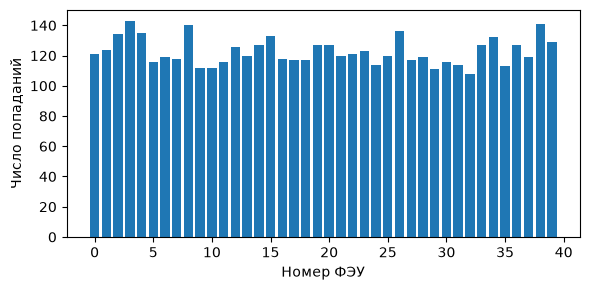

Относительный разброс: 7.1% (ожидаемый статистический: 9.0%)


In [6]:
rng = np.random.default_rng(2)
v = rng.normal(size=(1_000_000 // 5, 3))
pts = det.R * v / np.linalg.norm(v, axis=1, keepdims=True)
idx = det.pmt_index(pts)

counts = np.bincount(idx[idx >= 0], minlength=det.N)
plt.bar(np.arange(det.N), counts)
plt.xlabel('Номер ФЭУ')
plt.ylabel('Число попаданий')
plt.show()
print(f"Относительный разброс: {counts.std() / counts.mean():.1%} "
      f"(ожидаемый статистический: {1/np.sqrt(counts.mean()):.1%})")

## Визуализация (matplotlib)

Статичная картинка — её видно прямо на GitHub, в отличие от интерактивного виджета `k3d`.

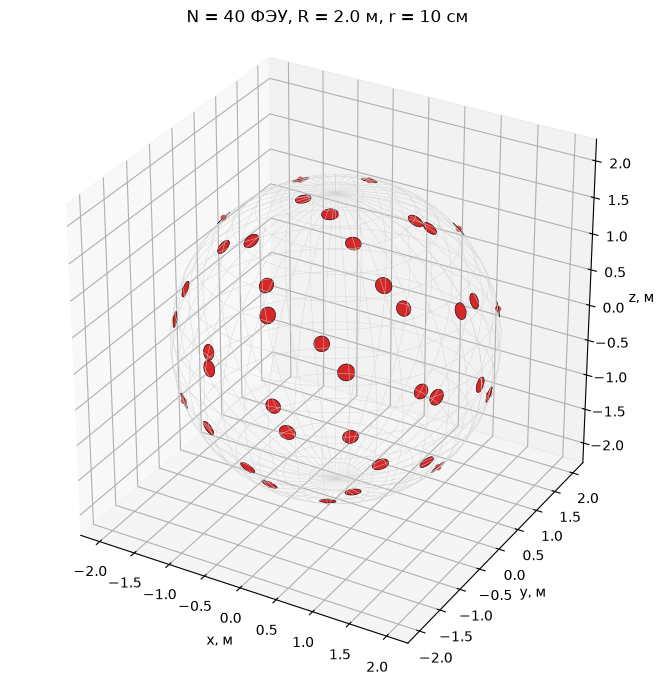

In [7]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection='3d')

# каркас сферы
u, w = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
ax.plot_wireframe(det.R*np.cos(u)*np.sin(w), det.R*np.sin(u)*np.sin(w), det.R*np.cos(w),
                  color='lightgray', linewidth=0.3)

# фотокатоды
ax.add_collection3d(Poly3DCollection(list(det.cathode_rims(32)),
                                     facecolor='tab:red', edgecolor='k', linewidths=0.4))
# оси ФЭУ (чтобы малые диски было видно)
ax.scatter(*det.pmt_pos.T, color='tab:red', s=12)

ax.set_box_aspect((1, 1, 1))
ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.set_zlabel('z, м')
ax.set_title(f'N = {det.N} ФЭУ, R = {det.R} м, r = {det.r*100:.0f} см')
plt.show()